# Expérience 1 — XGBoost : apport du mois et de la saison

**Question :** à variables météo et historiques identiques, le calendrier améliore-t-il
la prévision de Tmax à J+1 à Nantes ? On ajoute des **colonnes**, pas de nouvelles observations.

On compare trois variantes : météo et historiques seuls, + mois cyclique,
+ saison météorologique. Une persistance Tmax(J+1) = Tmax(J) sert de référence.
Le voisinage géographique est réservé à l'expérience suivante.

Les agrégats complets de J sont supposés disponibles en fin de J. Les observations
ERA5 sont rétrospectives ; leur délai de publication empêche d'assimiler ce test
à une prévision opérationnelle en temps réel. La cible reste une température,
pas encore un événement de canicule.


## 1. Environnement et données

Depuis la racine : `nix develop`, puis `jupyter lab experiments`.
Choisir le noyau **Python (STASC Nix)** après avoir relancé l'environnement.
Le CSV local est commun au notebook précédent ; il n'est ni modifié ni téléchargé ici.


In [1]:
from pathlib import Path
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from experiment_utils import (
    NON_FEATURES, HISTORY_FEATURES, prepare_daily_data, build_supervised,
    chronological_masks, add_calendar_features,
)

DATA_PATH = PROJECT_ROOT / "data/nantes_weather_daily.csv"
OUTPUT_DIR = PROJECT_ROOT / "experiments/plots_xgboost_calendar"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Python {platform.python_version()} ; sklearn {sklearn.__version__} ; XGBoost {xgb.__version__}")


Python 3.10.6 ; sklearn 1.1.1 ; XGBoost 1.5.2


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


In [2]:
data = prepare_daily_data(pd.read_csv(DATA_PATH, parse_dates=["date"]))
base = build_supervised(data, include_history=True)
model_data = add_calendar_features(base)
weather_features = [c for c in base.columns if c not in NON_FEATURES]
feature_sets = {
    "meteo_seule": weather_features,
    "mois_cyclique": weather_features + ["month_sin", "month_cos"],
    "saison": weather_features + [
        "season_winter", "season_spring", "season_summer", "season_autumn"
    ],
}
print(f"Observations brutes : {len(data)} ; paires utilisables : {len(model_data)}")
print(f"Période : {data['date'].min().date()} → {data['date'].max().date()}")
print("Cellule ERA5 :", data[["lat", "lon"]].drop_duplicates().to_dict("records"))
display(pd.DataFrame({"nombre_variables": {k: len(v) for k, v in feature_sets.items()}}))
display(model_data[["date", "target_date", "temperature_max", "tmax_next_day", "month_sin", "month_cos"]].head())
assert (model_data["target_date"] - model_data["date"]).eq(pd.Timedelta(days=1)).all()


Observations brutes : 997 ; paires utilisables : 994
Période : 2024-01-01 → 2026-09-23
Cellule ERA5 : [{'lat': 47.25, 'lon': -1.5}]


,nombre_variables
meteo_seule,18
mois_cyclique,20
saison,22


,date,target_date,temperature_max,tmax_next_day,month_sin,month_cos
0,2024-01-03,2024-01-04,12.8,13.3,0.0,1.0
1,2024-01-04,2024-01-05,13.3,10.9,0.0,1.0
2,2024-01-05,2024-01-06,10.9,9.4,0.0,1.0
3,2024-01-06,2024-01-07,9.4,6.7,0.0,1.0
4,2024-01-07,2024-01-08,6.7,4.0,0.0,1.0


## 2. Encodage du calendrier et protocole fixé avant les scores

Le calendrier est celui de **J+1**, connu dès J, y compris aux changements de mois.
Le mois est encodé par `sin(2π(m−1)/12)` et `cos(2π(m−1)/12)` pour rapprocher
décembre et janvier. Les saisons de l'hémisphère Nord sont encodées en quatre
indicatrices : hiver = décembre–février, printemps = mars–mai, été = juin–août,
automne = septembre–novembre. Aucune statistique de température future n'intervient.
La saison étant dérivée du mois, on teste les deux représentations séparément.

Séparation chronologique approximative **60 % entraînement / 20 % validation / 20 % test**.
Aux deux frontières, on exclut de l'entraînement les lignes dont la cible atteint
la période suivante. On entraîne un modèle fixe, sans mise à jour quotidienne ;
les observations passées deviennent néanmoins disponibles pour construire les retards du jour.
XGBoost utilise des arbres : aucune standardisation n'est nécessaire.

Même configuration pour chaque variante. L'arrêt anticipé utilise seulement la validation ;
la variante retenue est celle de MAE de validation minimale, météo seule en cas d'égalité.
Après ce choix, on réentraîne sur entraînement + validation avec le nombre d'arbres
retenu, puis on calcule les scores du test sans revenir sur le choix.


In [3]:
n = len(model_data)
if n < 100:
    raise ValueError("Historique trop court pour cette séparation à trois périodes.")
VALIDATION_START = model_data.iloc[int(n * 0.6)]["date"]
TEST_START = model_data.iloc[int(n * 0.8)]["date"]
train_mask = model_data["target_date"] < VALIDATION_START
val_mask = (model_data["date"] >= VALIDATION_START) & (model_data["target_date"] < TEST_START)
test_mask = model_data["date"] >= TEST_START
development_mask = model_data["target_date"] < TEST_START
assert not (train_mask & val_mask).any()
assert not (development_mask & test_mask).any()
assert model_data.loc[train_mask, "target_date"].max() < model_data.loc[val_mask, "date"].min()
assert model_data.loc[val_mask, "target_date"].max() < model_data.loc[test_mask, "date"].min()

periods = {"train": train_mask, "validation": val_mask, "test": test_mask}
display(pd.DataFrame([
    {"periode": name, "n": int(mask.sum()),
     "premiere_observation": model_data.loc[mask, "date"].min(),
     "derniere_cible": model_data.loc[mask, "target_date"].max()}
    for name, mask in periods.items()
]))
print("Couverture par saison (chaque période ne couvre pas forcément une année) :")
display(pd.DataFrame({
    name: model_data.loc[mask, [c for c in model_data if c.startswith("season_")]].sum()
    for name, mask in periods.items()
}))
y = model_data["tmax_next_day"]


,periode,n,premiere_observation,derniere_cible
0,train,595,2024-01-03,2025-08-20
1,validation,198,2025-08-21,2026-03-07
2,test,199,2026-03-08,2026-09-23


Couverture par saison (chaque période ne couvre pas forcément une année) :


,train,validation,test
season_winter,147,90,0
season_spring,184,7,84
season_summer,173,10,92
season_autumn,91,91,23


## 3. Entraînement et choix sur la validation

On limite la profondeur à 3 sur ce petit historique, avec régularisation et graine fixées.
Le maximum est de 1 000 arbres et la patience de 50 tours, avec MAE de validation.
La configuration n'est pas optimisée sur le test. L'API d'arrêt anticipé est adaptée
à XGBoost 1.5.2 fourni par le Nix épinglé et aux versions récentes.


In [4]:
PARAMS = dict(
    objective="reg:squarederror", tree_method="hist",
    learning_rate=0.03, max_depth=3, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=5.0, random_state=42, n_jobs=2,
)
XGB_VERSION = tuple(int(part) for part in xgb.__version__.split(".")[:2])

def fit_with_validation(columns):
    options = dict(PARAMS, n_estimators=1000)
    fit_options = dict(
        eval_set=[(model_data.loc[val_mask, columns].to_numpy(), y.loc[val_mask].to_numpy())],
        verbose=False,
    )
    # XGBoost >= 1.6 place ces paramètres dans le constructeur.
    if XGB_VERSION >= (1, 6):
        options.update(eval_metric="mae", early_stopping_rounds=50)
    else:
        fit_options.update(eval_metric="mae", early_stopping_rounds=50)
    estimator = xgb.XGBRegressor(**options)
    estimator.fit(
        model_data.loc[train_mask, columns].to_numpy(),
        y.loc[train_mask].to_numpy(), **fit_options,
    )
    return estimator

validation_models = {}
validation_rows = []
for name, columns in feature_sets.items():
    estimator = fit_with_validation(columns)
    validation_models[name] = estimator
    prediction = estimator.predict(model_data.loc[val_mask, columns].to_numpy())
    validation_rows.append({
        "variante": name,
        "MAE_validation_C": mean_absolute_error(y.loc[val_mask], prediction),
        "nombre_arbres": int(estimator.best_iteration + 1),
    })
validation_scores = pd.DataFrame(validation_rows).set_index("variante")
selected_variant = validation_scores["MAE_validation_C"].idxmin()
validation_persistence = mean_absolute_error(
    y.loc[val_mask], model_data.loc[val_mask, "temperature_max"]
)
display(validation_scores)
print(f"MAE de persistance sur validation : {validation_persistence:.3f} °C")
print(f"Variante retenue AVANT les scores du test : {selected_variant}")


,MAE_validation_C,nombre_arbres
variante,,
meteo_seule,1.568891,126
mois_cyclique,1.523259,130
saison,1.556417,137


MAE de persistance sur validation : 1.721 °C
Variante retenue AVANT les scores du test : mois_cyclique


## 4. Réentraînement et évaluation finale commune

On présente toutes les variantes comme une analyse d'ablation, en conservant le choix
fait sur validation même si une autre obtient un meilleur résultat sur le test.
La MAE est la métrique principale ; RMSE et R² la complètent.
Le gain est `MAE(persistance) − MAE(modèle)` : un gain positif indique une amélioration.
Cette expérience a une coupure différente du notebook initial ; on compare les variantes
**dans ce notebook**, pas directement leurs scores à ceux de l'ancien test.


In [5]:
final_models = {}
test_predictions = {"persistance": model_data.loc[test_mask, "temperature_max"].to_numpy()}
for name, columns in feature_sets.items():
    count = int(validation_scores.loc[name, "nombre_arbres"])
    estimator = xgb.XGBRegressor(**PARAMS, n_estimators=count)
    estimator.fit(
        model_data.loc[development_mask, columns].to_numpy(),
        y.loc[development_mask].to_numpy(),
    )
    final_models[name] = estimator
    test_predictions[name] = estimator.predict(model_data.loc[test_mask, columns].to_numpy())

y_test = y.loc[test_mask].to_numpy()
test_scores = pd.DataFrame([
    {"modele": name, "MAE_C": mean_absolute_error(y_test, prediction),
     "RMSE_C": np.sqrt(mean_squared_error(y_test, prediction)),
     "R2": r2_score(y_test, prediction)}
    for name, prediction in test_predictions.items()
]).set_index("modele")
test_scores["gain_vs_persistance_C"] = test_scores.loc["persistance", "MAE_C"] - test_scores["MAE_C"]
test_scores["gain_vs_xgb_sans_calendrier_C"] = test_scores.loc["meteo_seule", "MAE_C"] - test_scores["MAE_C"]
test_scores["retenu_sur_validation"] = test_scores.index == selected_variant
display(test_scores)

predictions = model_data.loc[test_mask, ["date", "target_date", "temperature_max", "tmax_next_day"]].copy()
for name, prediction in test_predictions.items():
    predictions[name] = prediction


,MAE_C,RMSE_C,R2,gain_vs_persistance_C,gain_vs_xgb_sans_calendrier_C,retenu_sur_validation
modele,,,,,,
persistance,2.186432,2.951850,0.844572,0.000000,0.743756,False
meteo_seule,2.930188,4.057662,0.706307,-0.743756,0.000000,False
mois_cyclique,2.993503,4.054754,0.706728,-0.807071,-0.063315,True
saison,2.946007,4.013365,0.712685,-0.759575,-0.015819,False


## 5. Où le calendrier aide-t-il ?

On affiche les erreurs par mois de la **date cible**, avec le nombre de jours.
Le premier ou le dernier mois peuvent être incomplets. Ces diagnostics décrivent
les erreurs ; ils ne servent pas à modifier les variables ni les paramètres.


,n_jours,persistance,meteo_seule,mois_cyclique,saison
mois,,,,,
2026-03,23,1.439130,1.394711,1.393177,1.471184
2026-04,30,2.423333,2.338377,2.495870,2.389663
2026-05,31,2.158065,2.925201,3.095605,3.150864
2026-06,30,2.770000,4.122654,4.032870,4.048025
2026-07,31,2.129032,4.312167,4.197363,4.062440
2026-08,31,2.045161,2.918234,2.929835,2.772624
2026-09,23,2.169565,1.842370,2.212825,2.161899


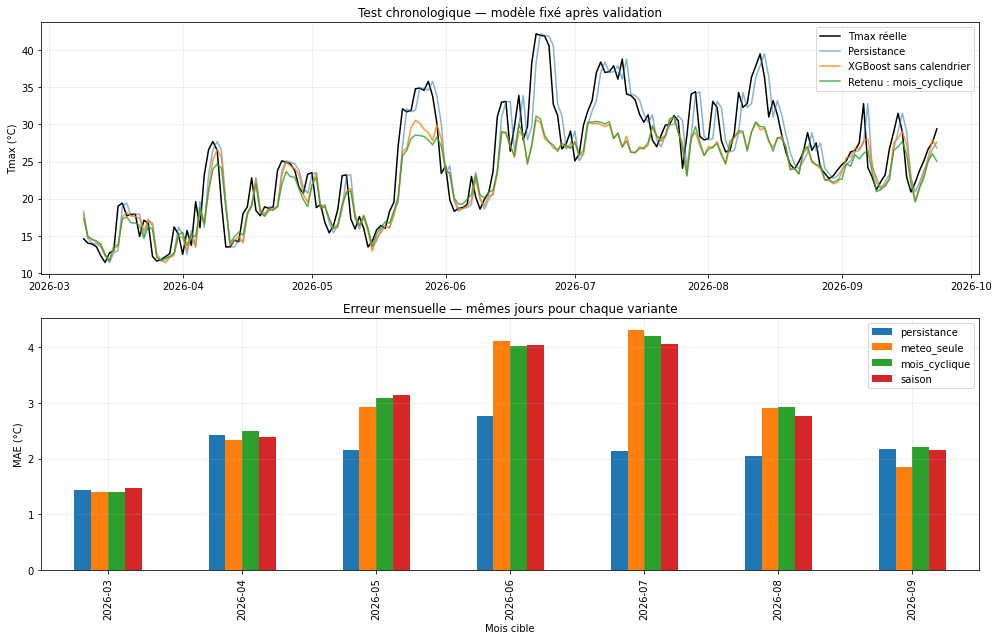

In [6]:
monthly_rows = []
for month, group in predictions.groupby(predictions["target_date"].dt.to_period("M")):
    row = {"mois": str(month), "n_jours": len(group)}
    for name in test_predictions:
        row[name] = mean_absolute_error(group["tmax_next_day"], group[name])
    monthly_rows.append(row)
monthly_scores = pd.DataFrame(monthly_rows).set_index("mois")
display(monthly_scores)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(predictions["target_date"], y_test, label="Tmax réelle", color="black", linewidth=1.5)
axes[0].plot(predictions["target_date"], predictions["persistance"], label="Persistance", alpha=0.55)
axes[0].plot(predictions["target_date"], predictions["meteo_seule"], label="XGBoost sans calendrier", alpha=0.8)
if selected_variant != "meteo_seule":
    axes[0].plot(predictions["target_date"], predictions[selected_variant], label=f"Retenu : {selected_variant}", alpha=0.8)
axes[0].set(ylabel="Tmax (°C)", title="Test chronologique — modèle fixé après validation")
axes[0].legend()
monthly_scores[list(test_predictions)].plot.bar(ax=axes[1])
axes[1].set(ylabel="MAE (°C)", xlabel="Mois cible", title="Erreur mensuelle — mêmes jours pour chaque variante")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 6. Lecture du résultat et suite

Un meilleur score ponctuel ne prouve pas à lui seul un gain reproductible.
Avec moins de trois années de données, la validation et le test ne couvrent pas
chacun un cycle annuel complet. Le calendrier peut aider pour certaines saisons
et dégrader les autres ; il ne remplace pas l'information météo amont.

Ces dates ont déjà pu être vues dans les explorations du premier notebook : le test
est séparé dans ce protocole, mais ce n'est pas une confirmation prospective indépendante.
Ne pas revenir optimiser sur ses erreurs. Il faudra ensuite confirmer sur plusieurs
fenêtres temporelles et sur une période future non consultée.

Pour l'expérience géographique suivante, conserver ce témoin et les mêmes dates :
ajouter les observations de cellules voisines à J par jointure sur **date + cellule**,
puis passer en colonnes par voisin. Ne jamais décaler une table empilant plusieurs
localisations avec un `shift` global. Aucun voisin n'est ajouté ici.

Références : [fuites de données et pipelines](https://scikit-learn.org/stable/common_pitfalls.html),
[arrêt anticipé XGBoost](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html).


In [7]:
# Diagnostic descriptif après évaluation : couverture des températures cibles.
display(pd.DataFrame([
    {"periode": name, "Tmax_cible_min_C": y.loc[mask].min(),
     "Tmax_cible_max_C": y.loc[mask].max()}
    for name, mask in {**periods, "train_plus_validation": development_mask}.items()
]))
print("Comparer ces plages pour repérer un éventuel décalage de distribution ; ne pas réoptimiser sur le test.")


,periode,Tmax_cible_min_C,Tmax_cible_max_C
0,train,-0.1,37.4
1,validation,1.4,33.0
2,test,11.4,42.2
3,train_plus_validation,-0.1,37.4


Comparer ces plages pour repérer un éventuel décalage de distribution ; ne pas réoptimiser sur le test.


In [8]:
gain = test_scores.loc[selected_variant, "gain_vs_xgb_sans_calendrier_C"]
print(f"Choix sur validation : {selected_variant}")
print(f"MAE test : {test_scores.loc[selected_variant, 'MAE_C']:.3f} °C")
print(f"Gain test face à XGBoost sans calendrier : {gain:+.3f} °C")
if selected_variant == "meteo_seule":
    print("La validation ne retient pas l'ajout du calendrier dans ce protocole.")
elif gain > 0:
    print("Le calendrier retenu réduit l'erreur sur ce test ; gain à confirmer sur d'autres périodes.")
else:
    print("Le choix de validation ne réduit pas l'erreur sur ce test : pas de gain confirmé ici.")


Choix sur validation : mois_cyclique
MAE test : 2.994 °C
Gain test face à XGBoost sans calendrier : -0.063 °C
Le choix de validation ne réduit pas l'erreur sur ce test : pas de gain confirmé ici.
